<a href="https://colab.research.google.com/github/3b232076/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HW3 四資四乙 3B232076-陳韻如

## 載入套件

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [20]:
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## a.資料預處理

In [22]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

In [23]:
# 顯示資料形狀
print("訓練圖片 shape：", x_train.shape)
print("訓練標籤 shape：", y_train.shape)
print("測試圖片 shape：", x_test.shape)
print("測試標籤 shape：", y_test.shape)

訓練圖片 shape： (60000, 28, 28)
訓練標籤 shape： (60000,)
測試圖片 shape： (10000, 28, 28)
測試標籤 shape： (10000,)


## 正規化與 reshape

In [24]:
# 將像素值從 0~255 轉換成 0~1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 將 28×28 圖片轉換成 784 個特徵
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

print("正規化後訓練資料：", x_train.shape)
print("正規化後測試資料：", x_test.shape)

正規化後訓練資料： (60000, 784)
正規化後測試資料： (10000, 784)


## 顯示三張訓練圖片及真實標籤

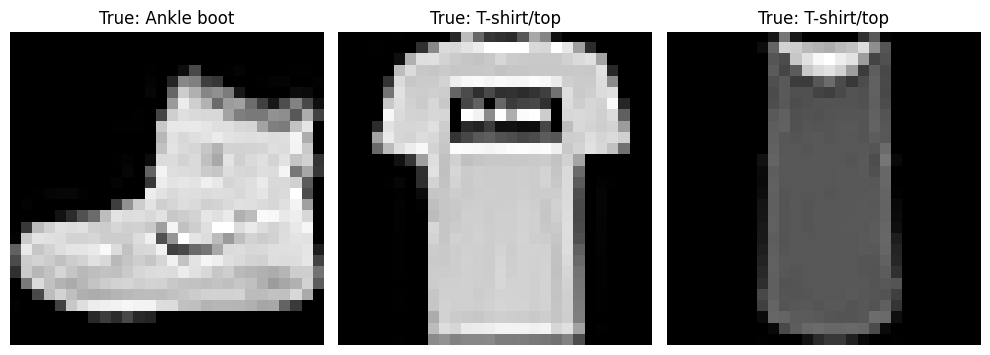

In [25]:
labels = ["T-shirt/top", "Trouser", "Pullover",
      "Dress", "Coat", "Sandal",
      "Shirt", "Sneaker", "Bag",
      "Ankle boot"]

# 顯示訓練圖片與真實標籤

plt.figure(figsize=(10, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)

    # 將圖片還原成 28×28 顯示
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title("True: " + labels[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 切分驗證資料及 One-hot encoding

In [26]:
# 切分訓練資料與驗證資料

x_train, x_val, y_train_num, y_val_num = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("訓練資料：", x_train.shape)
print("驗證資料：", x_val.shape)
print("測試資料：", x_test.shape)

# One-hot encoding

y_train = to_categorical(y_train_num, 10)
y_val = to_categorical(y_val_num, 10)
y_test_oh = to_categorical(y_test, 10)

print("訓練標籤：", y_train.shape)
print("驗證標籤：", y_val.shape)
print("測試標籤：", y_test_oh.shape)

訓練資料： (48000, 784)
驗證資料： (12000, 784)
測試資料： (10000, 784)
訓練標籤： (48000, 10)
驗證標籤： (12000, 10)
測試標籤： (10000, 10)


## b.建立神經網路模型

In [27]:
# 輸入層
model = Sequential([
    Input(shape=(784,), name="input_layer"),

    Dense(512, activation="relu", name="hidden_layer_1"),   # 第一隱藏層
    Dropout(0.2, name="dropout_1"),

    Dense(256, activation="relu", name="hidden_layer_2"),   # 第二隱藏層
    Dropout(0.2, name="dropout_2"),

    Dense(128, activation="relu", name="hidden_layer_3"),   # 第三隱藏層
    Dropout(0.2, name="dropout_3"),

    Dense(64, activation="relu", name="hidden_layer_4"),    # 第四隱藏層
    Dropout(0.2, name="dropout_4"),

    Dense(10, activation="softmax", name="output_layer")    # 輸出層
])

In [28]:
# 編譯模型
model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# 顯示模型架構
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_3 (Dense)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_4 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 575,050 (2.19 MB)

 Trainable params: 575,050 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

### 神經網路參數量計算

參數量 = 輸入神經元數 × 輸出神經元數 + 輸出神經元數

1. 第一隱藏層：784 × 512 + 512 = 401,920
2. 第二隱藏層：512 × 256 + 256 = 131,328
3. 第三隱藏層：256 × 128 + 128 = 32,896
4. 第四隱藏層：128 × 64 + 64 = 8256
5. 輸出層：64 × 10 + 10 = 650

Dropout 層沒有可訓練參數。因此，模型總參數量為 575,050。

## 顯示批次輸入與每一層的輸出 shape

In [29]:
# 顯示每一層的輸出 shape

batch_size = 128

# 取出一批資料
sample_batch = tf.convert_to_tensor(x_train[:batch_size])

print("批次輸入 shape：", sample_batch.shape)

# 觀察每一層的輸出
x = sample_batch

for layer in model.layers:
    x = layer(x, training=False)
    print(layer.name, "output shape：", x.shape)

批次輸入 shape： (128, 784)
hidden_layer_1 output shape： (128, 512)
dropout_1 output shape： (128, 512)
hidden_layer_2 output shape： (128, 256)
dropout_2 output shape： (128, 256)
hidden_layer_3 output shape： (128, 128)
dropout_3 output shape： (128, 128)
hidden_layer_4 output shape： (128, 64)
dropout_4 output shape： (128, 64)
output_layer output shape： (128, 10)


## c.訓練神經網路模型

In [30]:
batch_size = 128
epochs = 60

history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_data=(x_val, y_val),
    verbose=1
)

Epoch 1/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 25ms/step - accuracy: 0.7554 - loss: 0.6834 - val_accuracy: 0.8406 - val_loss: 0.4354
Epoch 2/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.8378 - loss: 0.4577 - val_accuracy: 0.8656 - val_loss: 0.3720
Epoch 3/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8538 - loss: 0.4089 - val_accuracy: 0.8674 - val_loss: 0.3682
Epoch 4/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.8653 - loss: 0.3788 - val_accuracy: 0.8790 - val_loss: 0.3334
Epoch 5/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8702 - loss: 0.3581 - val_accuracy: 0.8826 - val_loss: 0.3283
Epoch 6/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.8740 - loss: 0.3443 - val_accuracy: 0.8815 - val_loss: 0.3331
Epoch 7/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8789 - loss: 0.3317 - val_accuracy: 0.8864 - val_loss: 0.3118
Epoch 8/60
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.8852 - loss: 0.3181 - val_acc

## d.顯示 Loss 與 Accuracy 折線圖

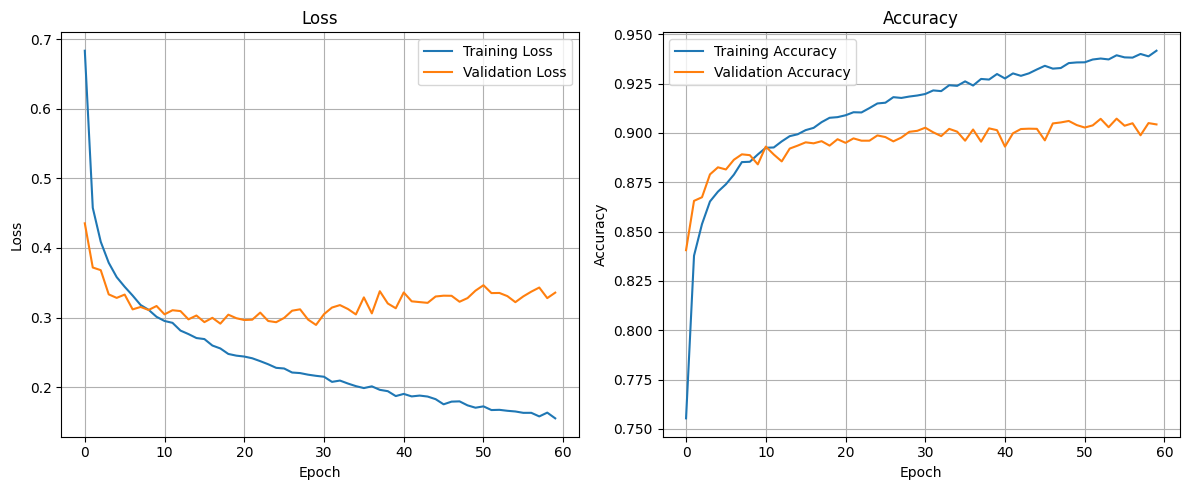

In [31]:
# 顯示訓練過程

plt.figure(figsize=(12, 5))

# Loss 折線圖
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Accuracy 折線圖
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## e.使用全部測試資料評估準確率

In [32]:
# 評估模型準確率

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test_oh,
    verbose=1
)

print("測試資料 Loss：", round(test_loss, 4))
print("測試資料 Accuracy：", f"{test_accuracy * 100:.2f}%")

if test_accuracy >= 0.90:
    print("已達到老師要求的 90% 準確率。")
else:
    print("尚未達到 90%，需要再調整模型。")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8969 - loss: 0.3775
測試資料 Loss： 0.3775
測試資料 Accuracy： 89.69%
尚未達到 90%，需要再調整模型。


## f.進行預測

In [33]:
# 使用全部測試資料進行預測
y_pred_prob = model.predict(x_test, batch_size=128, verbose=1)

# 將機率最高的類別轉換成數字標籤
y_pred = np.argmax(y_pred_prob, axis=1)

print("預測機率 shape：", y_pred_prob.shape)
print("預測類別 shape：", y_pred.shape)

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
預測機率 shape： (10000, 10)
預測類別 shape： (10000,)


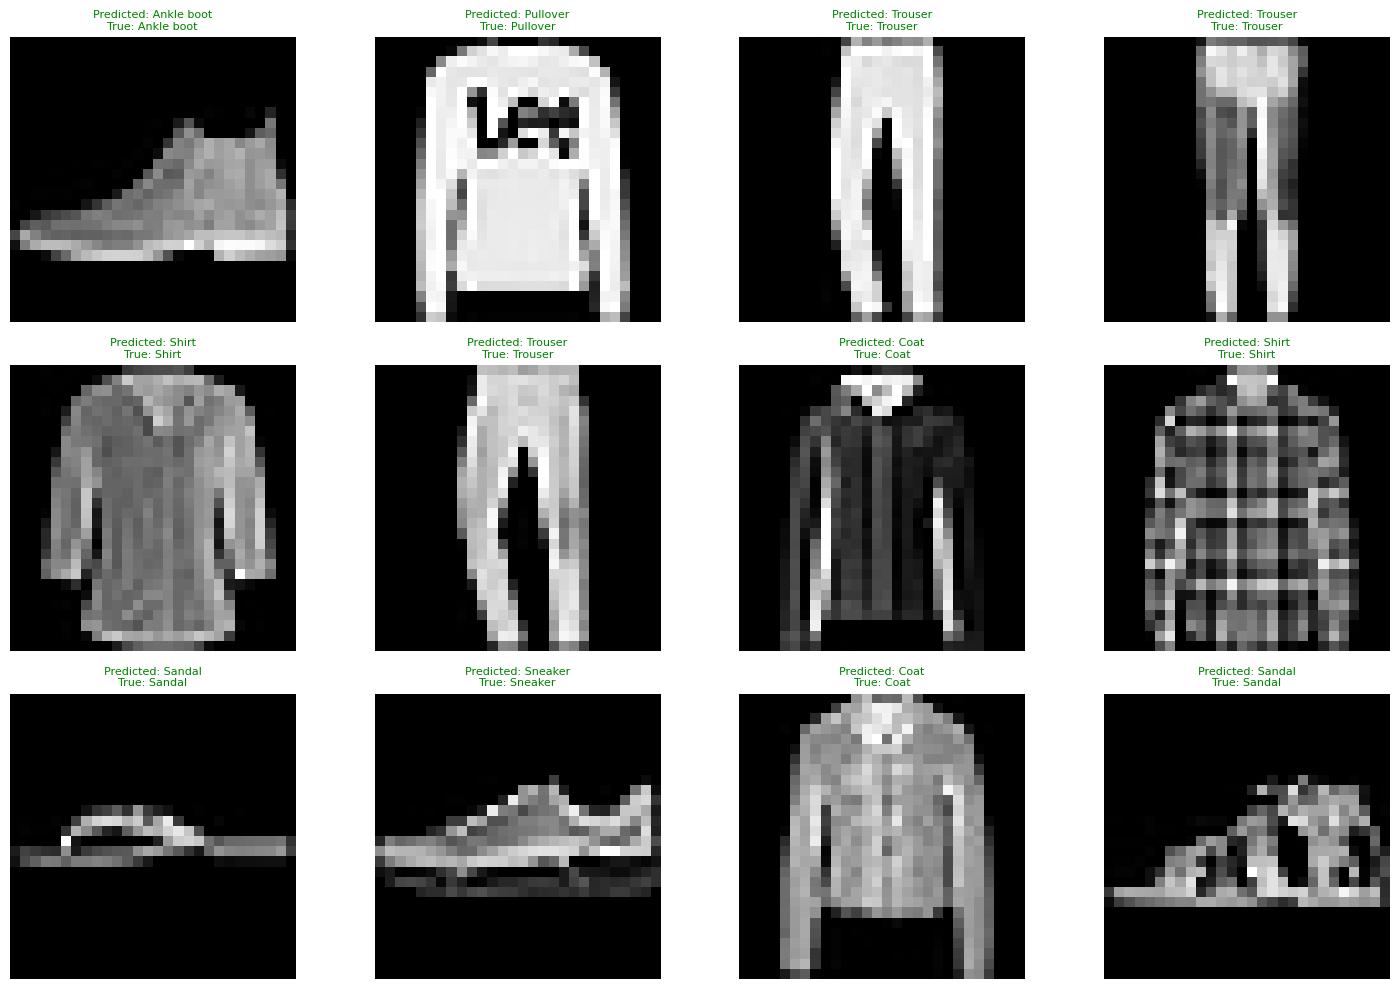

In [34]:
# 顯示測試圖片與標籤名稱

num_images = 12

plt.figure(figsize=(15, 10))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")

    predicted_label = labels[y_pred[i]]
    true_label = labels[y_test[i]]

    if y_pred[i] == y_test[i]:
        color = "green"
    else:
        color = "red"

    plt.title(
        f"Predicted: {predicted_label}\nTrue: {true_label}",
        color=color,
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

## g.混淆矩陣(Confusion Matrix)

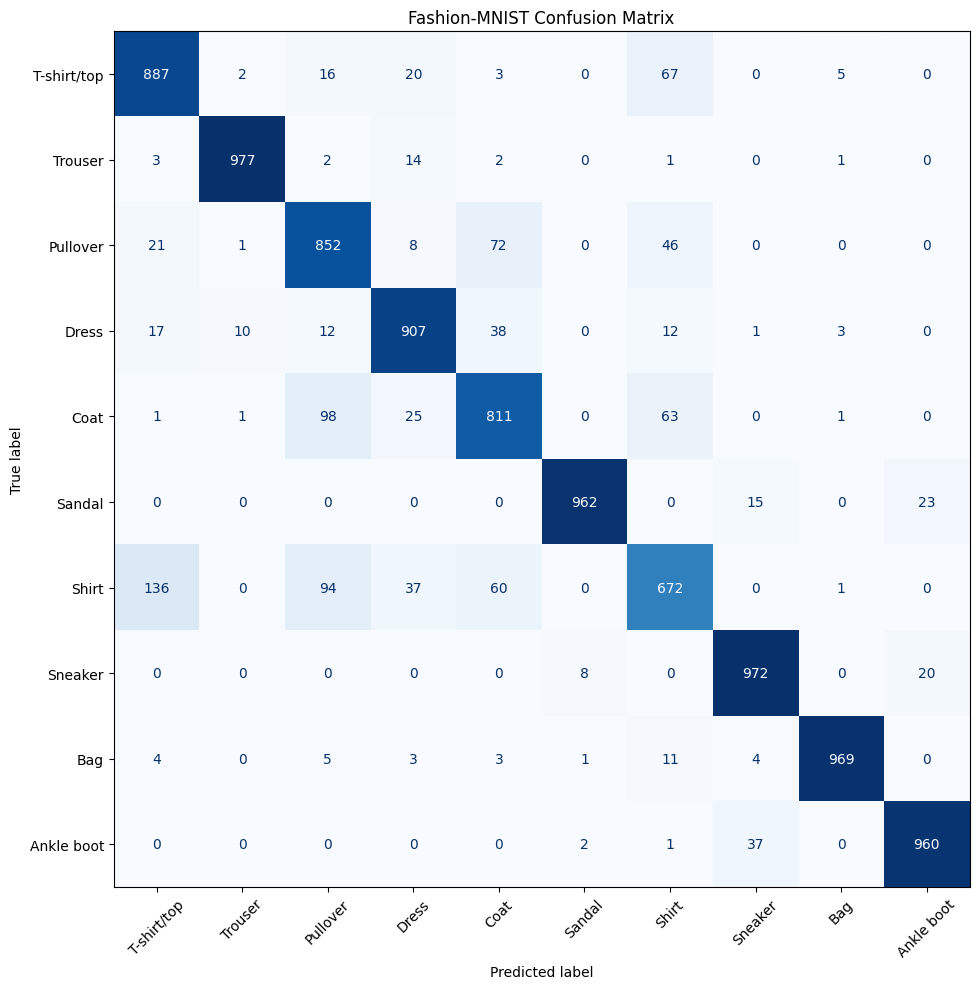

In [35]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(10)
)

display_labels = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Fashion-MNIST Confusion Matrix")
plt.tight_layout()
plt.show()

## h.儲存完整模型

In [36]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
%cd /content/drive/MyDrive/Colab Notebooks/

/content/drive/MyDrive/Colab Notebooks


In [38]:
model.save('fashion_mnist_model.keras')